In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel("../data/raw/Telco_customer_churn.xlsx")
print(df.shape)
df.head()

(7043, 33)


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Internet Service   7043 

In [3]:
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
print(df.columns.tolist())

['customerid', 'count', 'country', 'state', 'city', 'zip_code', 'lat_long', 'latitude', 'longitude', 'gender', 'senior_citizen', 'partner', 'dependents', 'tenure_months', 'phone_service', 'multiple_lines', 'internet_service', 'online_security', 'online_backup', 'device_protection', 'tech_support', 'streaming_tv', 'streaming_movies', 'contract', 'paperless_billing', 'payment_method', 'monthly_charges', 'total_charges', 'churn_label', 'churn_value', 'churn_score', 'cltv', 'churn_reason']


In [4]:
df["total_charges"] = pd.to_numeric(df["total_charges"], errors="coerce")
print(df["total_charges"].isna().sum())
df[df["total_charges"].isna()][["tenure_months", "total_charges"]]

11


,tenure_months,total_charges
2234,0,NaN
2438,0,NaN
2568,0,NaN
2667,0,NaN
2856,0,NaN
4331,0,NaN
4687,0,NaN
5104,0,NaN
5719,0,NaN
6772,0,NaN


In [5]:
df["total_charges"] = df["total_charges"].fillna(0)
df.isna().sum().sort_values(ascending=False).head()

churn_reason    5174
customerid         0
count              0
state              0
country            0
dtype: int64

In [6]:
print(df["churn_value"].mean())
df["churn_value"].value_counts()

0.2653698707936959


churn_value
0    5174
1    1869
Name: count, dtype: int64

In [7]:
for col in ["contract", "internet_service", "payment_method"]:
    print(df.groupby(col)["churn_value"].mean().sort_values(ascending=False), "\n")

contract
Month-to-month    0.427097
One year          0.112695
Two year          0.028319
Name: churn_value, dtype: float64 

internet_service
Fiber optic    0.418928
DSL            0.189591
No             0.074050
Name: churn_value, dtype: float64 

payment_method
Electronic check             0.452854
Mailed check                 0.191067
Bank transfer (automatic)    0.167098
Credit card (automatic)      0.152431
Name: churn_value, dtype: float64 



In [8]:
df.groupby(pd.cut(df["tenure_months"], [-1, 6, 12, 24, 48, 72]))["churn_value"].mean()

C:\Users\yelle\AppData\Local\Temp\ipykernel_38084\2640320632.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(pd.cut(df["tenure_months"], [-1, 6, 12, 24, 48, 72]))["churn_value"].mean()


tenure_months
(-1, 6]     0.529372
(6, 12]     0.358865
(12, 24]    0.287109
(24, 48]    0.203890
(48, 72]    0.095132
Name: churn_value, dtype: float64

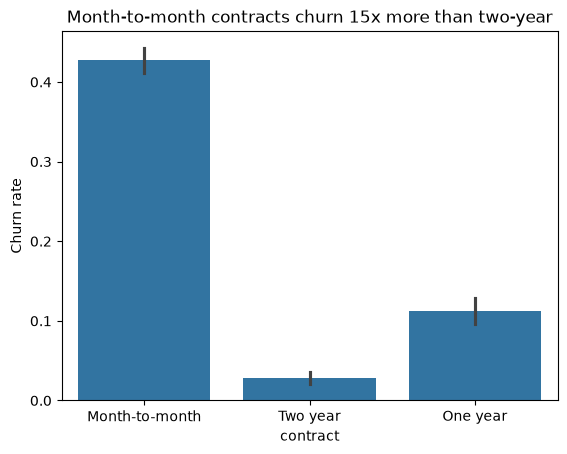

In [9]:
sns.barplot(data=df, x="contract", y="churn_value")
plt.title("Month-to-month contracts churn 15x more than two-year")
plt.ylabel("Churn rate")
plt.show()

In [10]:
df.to_csv("../data/processed/telco_clean.csv", index=False)